### Data Understanding

In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
import sys
print(sys.version)

3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]


In [3]:
df=pd.read_csv(r"D:\Data Analysis\Project\Layoffs_Project\layoffs.csv")
df.head()

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
0,Atlassian,Sydney,Other,500.0,0.05,3/6/2023,Post-IPO,Australia,210.0
1,SiriusXM,New York City,Media,475.0,0.08,3/6/2023,Post-IPO,United States,525.0
2,Alerzo,Ibadan,Retail,400.0,NaN,3/6/2023,Series B,Nigeria,16.0
3,UpGrad,Mumbai,Education,120.0,NaN,3/6/2023,Unknown,India,631.0
4,Loft,Sao Paulo,Real Estate,340.0,0.15,3/3/2023,Unknown,Brazil,788.0


In [4]:
df.columns


Index(['company', 'location', 'industry', 'total_laid_off',
       'percentage_laid_off', 'date', 'stage', 'country',
       'funds_raised_millions'],
      dtype='str')

In [5]:
df.shape

(2361, 9)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2361 entries, 0 to 2360
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   company                2361 non-null   str    
 1   location               2361 non-null   str    
 2   industry               2357 non-null   str    
 3   total_laid_off         1621 non-null   float64
 4   percentage_laid_off    1576 non-null   float64
 5   date                   2360 non-null   str    
 6   stage                  2355 non-null   str    
 7   country                2361 non-null   str    
 8   funds_raised_millions  2152 non-null   float64
dtypes: float64(3), str(6)
memory usage: 166.1 KB


In [7]:
df.describe()

,total_laid_off,percentage_laid_off,funds_raised_millions
count,1621.000000,1576.000000,2152.000000
mean,238.358421,0.257917,822.454134
std,769.718801,0.255575,5593.961626
min,3.000000,0.000000,0.000000
25%,36.000000,0.100000,50.000000
50%,80.000000,0.170000,156.500000
75%,180.000000,0.300000,445.000000
max,12000.000000,1.000000,121900.000000


### Data Cleaning

In [8]:
df.isnull().sum()

company                    0
location                   0
industry                   4
total_laid_off           740
percentage_laid_off      785
date                       1
stage                      6
country                    0
funds_raised_millions    209
dtype: int64

In [9]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
2356    False
2357     True
2358     True
2359     True
2360     True
Length: 2361, dtype: bool

In [10]:
df.duplicated().sum()

np.int64(5)

In [11]:
df[df.duplicated()]

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
1492,Cazoo,London,Transportation,750.0,0.15,6/7/2022,Post-IPO,United Kingdom,2000.0
2357,Yahoo,SF Bay Area,Consumer,1600.0,0.20,2/9/2023,Acquired,United States,6.0
2358,Hibob,Tel Aviv,HR,70.0,0.30,3/30/2020,Series A,Israel,45.0
2359,Casper,New York City,Retail,NaN,NaN,9/14/2021,Post-IPO,United States,339.0
2360,Wildlife Studios,Sao Paulo,Consumer,300.0,0.20,11/28/2022,Unknown,Brazil,260.0


In [12]:
df =df.drop_duplicates()

In [13]:
df.shape

(2356, 9)

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.isnull().sum()

company                    0
location                   0
industry                   4
total_laid_off           739
percentage_laid_off      784
date                       1
stage                      6
country                    0
funds_raised_millions    209
dtype: int64

In [16]:
df[df['industry'].isnull()]

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
8,Airbnb,SF Bay Area,NaN,30.0,NaN,3/3/2023,Post-IPO,United States,6400.0
330,Bally's Interactive,Providence,NaN,NaN,0.15,1/18/2023,Post-IPO,United States,946.0
736,Juul,SF Bay Area,NaN,400.0,0.30,11/10/2022,Unknown,United States,1500.0
1595,Carvana,Phoenix,NaN,2500.0,0.12,5/10/2022,Post-IPO,United States,1600.0


In [17]:
df[df['company']=="Airbnb"]

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
8,Airbnb,SF Bay Area,NaN,30.0,NaN,3/3/2023,Post-IPO,United States,6400.0
1936,Airbnb,SF Bay Area,Travel,1900.0,0.25,5/5/2020,Private Equity,United States,5400.0


In [18]:
df[df['company']=='Carvana']

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
371,Carvana,Phoenix,Transportation,NaN,NaN,1/13/2023,Post-IPO,United States,1600.0
659,Carvana,Phoenix,Transportation,1500.0,0.08,11/18/2022,Post-IPO,United States,1600.0
1595,Carvana,Phoenix,NaN,2500.0,0.12,5/10/2022,Post-IPO,United States,1600.0


In [19]:
df[df['company']=='Juul']


,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
736,Juul,SF Bay Area,NaN,400.0,0.3,11/10/2022,Unknown,United States,1500.0
1937,Juul,SF Bay Area,Consumer,900.0,0.3,5/5/2020,Unknown,United States,1500.0


In [20]:

df[df['company']=="Bally's Interactive"]

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
330,Bally's Interactive,Providence,NaN,NaN,0.15,1/18/2023,Post-IPO,United States,946.0


In [21]:
df["industry"] = (
    df.groupby("company")["industry"]
      .transform(lambda x: x.fillna(x.mode()[0]) if not x.mode().empty else x)
)

In [22]:
df[df["industry"].isnull()]

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
330,Bally's Interactive,Providence,NaN,NaN,0.15,1/18/2023,Post-IPO,United States,946.0


In [23]:
df[df['company']=='Juul']

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
736,Juul,SF Bay Area,Consumer,400.0,0.3,11/10/2022,Unknown,United States,1500.0
1937,Juul,SF Bay Area,Consumer,900.0,0.3,5/5/2020,Unknown,United States,1500.0


In [24]:
df['industry'] = df['industry'].fillna('Unknown')

In [25]:
df[df["industry"].isnull()]

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions


In [26]:
df.isnull().sum()

company                    0
location                   0
industry                   0
total_laid_off           739
percentage_laid_off      784
date                       1
stage                      6
country                    0
funds_raised_millions    209
dtype: int64

In [27]:
df[df['total_laid_off'].isnull()]

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
9,Accolade,Seattle,Healthcare,NaN,NaN,3/3/2023,Post-IPO,United States,458.0
10,Indigo,Boston,Other,NaN,NaN,3/3/2023,Series F,United States.,1200.0
16,Flipkart,Bengaluru,Retail,NaN,NaN,3/2/2023,Acquired,India,12900.0
17,Kandela,Los Angeles,Consumer,NaN,1.0,3/2/2023,Acquired,United States,NaN
18,Truckstop.com,Boise,Logistics,NaN,NaN,3/2/2023,Acquired,United States,NaN
...,...,...,...,...,...,...,...,...,...
2340,Vacasa,Portland,Travel,NaN,NaN,3/20/2020,Series C,United States,526.0
2345,Anyvision,Tel Aviv,Security,NaN,NaN,3/19/2020,Series A,Israel,74.0
2346,Popin,New York City,Fitness,NaN,1.0,3/19/2020,Unknown,United States,13.0
2347,Tuft & Needle,Phoenix,Retail,NaN,NaN,3/19/2020,Acquired,United States,0.0


In [28]:
df.sort_values('total_laid_off',ascending=False)

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
281,Google,SF Bay Area,Consumer,12000.0,0.06,1/20/2023,Post-IPO,United States,26.0
749,Meta,SF Bay Area,Consumer,11000.0,0.13,11/9/2022,Post-IPO,United States,26000.0
314,Microsoft,Seattle,Other,10000.0,0.05,1/18/2023,Post-IPO,United States,1.0
681,Amazon,Seattle,Retail,10000.0,0.03,11/16/2022,Post-IPO,United States,108.0
39,Ericsson,Stockholm,Other,8500.0,0.08,2/24/2023,Post-IPO,Sweden,663.0
...,...,...,...,...,...,...,...,...,...
2340,Vacasa,Portland,Travel,NaN,NaN,3/20/2020,Series C,United States,526.0
2345,Anyvision,Tel Aviv,Security,NaN,NaN,3/19/2020,Series A,Israel,74.0
2346,Popin,New York City,Fitness,NaN,1.00,3/19/2020,Unknown,United States,13.0
2347,Tuft & Needle,Phoenix,Retail,NaN,NaN,3/19/2020,Acquired,United States,0.0


In [29]:
df[df['date'].isnull()]

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
2356,Blackbaud,Charleston,Other,500.0,0.14,NaN,Post-IPO,United States,NaN


In [30]:
df[df['company']=='Blackbaud']

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
2356,Blackbaud,Charleston,Other,500.0,0.14,NaN,Post-IPO,United States,NaN


In [31]:
df=df.dropna(subset=["date"])

In [32]:
df['date'].isnull().sum()

np.int64(0)

In [33]:
df["date"] = pd.to_datetime(df["date"],errors='coerce')

In [34]:
df.info()

<class 'pandas.DataFrame'>
Index: 2355 entries, 0 to 2355
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   company                2355 non-null   str           
 1   location               2355 non-null   str           
 2   industry               2355 non-null   str           
 3   total_laid_off         1616 non-null   float64       
 4   percentage_laid_off    1571 non-null   float64       
 5   date                   2355 non-null   datetime64[us]
 6   stage                  2349 non-null   str           
 7   country                2355 non-null   str           
 8   funds_raised_millions  2147 non-null   float64       
dtypes: datetime64[us](1), float64(3), str(5)
memory usage: 184.0 KB


In [35]:
df["year"] = df["date"].dt.year
df['month']=df['date'].dt.month
df.groupby('year')['company'].count()

year
2020     634
2021      44
2022    1211
2023     466
Name: company, dtype: int64

In [36]:
df['country'].unique()

<StringArray>
[           'Australia',        'United States',              'Nigeria',
                'India',               'Brazil',       'United States.',
               'France',              'Germany',               'Israel',
               'Sweden',       'United Kingdom',                'Japan',
          'South Korea',                'China',                'Italy',
            'Singapore',            'Indonesia',              'Estonia',
               'Canada',              'Ireland',              'Finland',
          'Netherlands',                'Spain',             'Portugal',
                'Chile',             'Colombia',            'Argentina',
           'Seychelles',              'Austria',               'Mexico',
          'Switzerland',                'Egypt',                'Kenya',
           'Luxembourg',               'Greece',               'Poland',
               'Norway',              'Belgium',              'Denmark',
            'Hong Kong',          'Ne

In [37]:
df['country']=df["country"].str.replace(".","",regex=False)

In [38]:
df['country'].unique()

<StringArray>
[           'Australia',        'United States',              'Nigeria',
                'India',               'Brazil',               'France',
              'Germany',               'Israel',               'Sweden',
       'United Kingdom',                'Japan',          'South Korea',
                'China',                'Italy',            'Singapore',
            'Indonesia',              'Estonia',               'Canada',
              'Ireland',              'Finland',          'Netherlands',
                'Spain',             'Portugal',                'Chile',
             'Colombia',            'Argentina',           'Seychelles',
              'Austria',               'Mexico',          'Switzerland',
                'Egypt',                'Kenya',           'Luxembourg',
               'Greece',               'Poland',               'Norway',
              'Belgium',              'Denmark',            'Hong Kong',
          'New Zealand',             

In [39]:
df["country"] = (
    df["country"]
      .str.lower()
      .str.strip()
      .str.replace(".", "", regex=False)
)

In [40]:
df['country'].unique()

<StringArray>
[           'australia',        'united states',              'nigeria',
                'india',               'brazil',               'france',
              'germany',               'israel',               'sweden',
       'united kingdom',                'japan',          'south korea',
                'china',                'italy',            'singapore',
            'indonesia',              'estonia',               'canada',
              'ireland',              'finland',          'netherlands',
                'spain',             'portugal',                'chile',
             'colombia',            'argentina',           'seychelles',
              'austria',               'mexico',          'switzerland',
                'egypt',                'kenya',           'luxembourg',
               'greece',               'poland',               'norway',
              'belgium',              'denmark',            'hong kong',
          'new zealand',             

In [41]:
df[df["stage"].isnull()]

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions,year,month
392,Verily,SF Bay Area,Healthcare,250.0,0.15,2023-01-11,NaN,united states,3500.0,2023,1
414,Relevel,Bengaluru,HR,40.0,0.20,2023-01-10,NaN,india,NaN,2023,1
831,Advata,Seattle,Healthcare,32.0,0.21,2022-10-28,NaN,united states,NaN,2022,10
837,Spreetail,Austin,Retail,NaN,NaN,2022-10-27,NaN,united states,NaN,2022,10
1183,Gatherly,Atlanta,Marketing,NaN,0.50,2022-07-31,NaN,united states,NaN,2022,7
1565,Zapp,London,Food,NaN,0.10,2022-05-25,NaN,united kingdom,300.0,2022,5


In [42]:
df[df['company']=='zapp']

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions,year,month


In [43]:
df[df['company']=='relevel']

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions,year,month


In [44]:
df['stage'] = df['stage'].fillna('Unknown')

In [45]:
df.groupby("stage").size()

stage
Acquired          171
Post-IPO          425
Private Equity     38
Seed               65
Series A          176
Series B          305
Series C          303
Series D          225
Series E          125
Series F           65
Series G           15
Series H           24
Series I            7
Series J            8
Subsidiary          5
Unknown           398
dtype: int64

In [46]:
df[df['funds_raised_millions'].isnull()]

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions,year,month
13,Ambev Tech,Blumenau,Food,50.0,NaN,2023-03-02,Acquired,brazil,NaN,2023,3
17,Kandela,Los Angeles,Consumer,NaN,1.00,2023-03-02,Acquired,united states,NaN,2023,3
18,Truckstop.com,Boise,Logistics,NaN,NaN,2023-03-02,Acquired,united states,NaN,2023,3
29,DUX Education,Bengaluru,Education,NaN,1.00,2023-02-28,Unknown,india,NaN,2023,2
47,Merative,Ann Arbor,Healthcare,200.0,0.10,2023-02-23,Acquired,united states,NaN,2023,2
...,...,...,...,...,...,...,...,...,...,...,...
2304,Rangle,Toronto,Product,78.0,0.30,2020-03-25,Unknown,canada,NaN,2020,3
2305,O'Reilly Media,SF Bay Area,Media,75.0,0.15,2020-03-25,Unknown,united states,NaN,2020,3
2317,Takl,Nashville,Consumer,130.0,NaN,2020-03-24,Unknown,united states,NaN,2020,3
2321,Flowr,Toronto,Retail,NaN,0.25,2020-03-24,Unknown,canada,NaN,2020,3


In [47]:
df['company']=(
    df['company']
    .str.strip()
    .str.lower()
    
    
)

### Data Validation

In [48]:
df.duplicated().sum()

np.int64(0)

In [49]:
df.isnull().sum()

company                    0
location                   0
industry                   0
total_laid_off           739
percentage_laid_off      784
date                       0
stage                      0
country                    0
funds_raised_millions    208
year                       0
month                      0
dtype: int64

In [50]:
df.info()

<class 'pandas.DataFrame'>
Index: 2355 entries, 0 to 2355
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   company                2355 non-null   str           
 1   location               2355 non-null   str           
 2   industry               2355 non-null   str           
 3   total_laid_off         1616 non-null   float64       
 4   percentage_laid_off    1571 non-null   float64       
 5   date                   2355 non-null   datetime64[us]
 6   stage                  2355 non-null   str           
 7   country                2355 non-null   str           
 8   funds_raised_millions  2147 non-null   float64       
 9   year                   2355 non-null   int32         
 10  month                  2355 non-null   int32         
dtypes: datetime64[us](1), float64(3), int32(2), str(5)
memory usage: 202.4 KB


In [51]:
df["country"].unique()

<StringArray>
[           'australia',        'united states',              'nigeria',
                'india',               'brazil',               'france',
              'germany',               'israel',               'sweden',
       'united kingdom',                'japan',          'south korea',
                'china',                'italy',            'singapore',
            'indonesia',              'estonia',               'canada',
              'ireland',              'finland',          'netherlands',
                'spain',             'portugal',                'chile',
             'colombia',            'argentina',           'seychelles',
              'austria',               'mexico',          'switzerland',
                'egypt',                'kenya',           'luxembourg',
               'greece',               'poland',               'norway',
              'belgium',              'denmark',            'hong kong',
          'new zealand',             

In [52]:
df.describe()

,total_laid_off,percentage_laid_off,date,funds_raised_millions,year,month
count,1616.000000,1571.000000,2355,2147.000000,2355.000000,2355.000000
mean,237.103342,0.258108,2022-02-02 23:52:39.745223,823.135210,2021.640764,5.959236
min,3.000000,0.000000,2020-03-11 00:00:00,0.000000,2020.000000,1.000000
25%,36.000000,0.100000,2020-08-19 12:00:00,50.000000,2020.000000,3.000000
50%,80.000000,0.170000,2022-08-01 00:00:00,156.000000,2022.000000,6.000000
75%,177.750000,0.300000,2022-12-01 00:00:00,445.000000,2022.000000,9.000000
max,12000.000000,1.000000,2023-03-06 00:00:00,121900.000000,2023.000000,12.000000
std,770.017732,0.255939,NaN,5600.341074,1.079288,3.437146


In [53]:
df.nunique().sort_values()

year                        4
month                      12
stage                      16
industry                   33
country                    59
percentage_laid_off        73
location                  190
total_laid_off            285
date                      483
funds_raised_millions     638
company                  1884
dtype: int64

In [54]:
df["stage"].unique()

<StringArray>
[      'Post-IPO',       'Series B',        'Unknown',       'Acquired',
       'Series F',       'Series E',       'Series A',     'Subsidiary',
       'Series C',       'Series G',       'Series D',           'Seed',
       'Series H', 'Private Equity',       'Series J',       'Series I']
Length: 16, dtype: str

In [55]:
df['stage']=(
    df['stage']
    .str.lower()
    .str.strip()
    .str.replace(".","",regex=False)
    
)

In [56]:
df['company'].unique()

<StringArray>
[    'atlassian',      'siriusxm',        'alerzo',        'upgrad',
          'loft', 'embark trucks',         'lendi',   'usertesting',
        'airbnb',      'accolade',
 ...
        'ejento',   'remote year',          'lola',     'anyvision',
         'popin', 'tuft & needle',     'flytedesk',      'help.com',
   'panda squad', 'tamara mellon']
Length: 1884, dtype: str

In [57]:
df['total_laid_off'].value_counts(normalize=True).mul(100).round(2)

total_laid_off
100.0    6.00
30.0     4.39
40.0     3.71
50.0     3.40
200.0    3.09
         ... 
349.0    0.06
194.0    0.06
108.0    0.06
406.0    0.06
375.0    0.06
Name: proportion, Length: 285, dtype: float64

### Exploratory Data Analysis (EDA)

In [58]:
print(f"Number of unique companies : {df['company'].nunique()}")
print(f"Number of unique countries : {df['country'].nunique()}")
print(f"Number of unique industries : {df['industry'].nunique()}")
print(f"Number of unique stages : {df['stage'].nunique()}")

Number of unique companies : 1884
Number of unique countries : 59
Number of unique industries : 33
Number of unique stages : 16


In [59]:
df.groupby('company')['total_laid_off'].sum().sort_values(ascending=False).head(10)


company
amazon         18150.0
google         12000.0
meta           11000.0
salesforce     10090.0
philips        10000.0
microsoft      10000.0
ericsson        8500.0
uber            7585.0
dell            6650.0
booking.com     4601.0
Name: total_laid_off, dtype: float64

In [60]:
df[df['company'] == 'google']

,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions,year,month
281,google,SF Bay Area,Consumer,12000.0,0.06,2023-01-20,post-ipo,united states,26.0,2023,1


In [61]:
df.groupby('country')['total_laid_off'].mean().sort_values(ascending=False).head(10)

country
netherlands    1913.333333
sweden          704.000000
china           656.111111
russia          400.000000
senegal         300.000000
india           285.658730
singapore       272.500000
indonesia       270.846154
spain           250.000000
finland         250.000000
Name: total_laid_off, dtype: float64

In [62]:
df.groupby('country')['company'].count().sort_values(ascending=False).head(10)

country
united states     1542
india              148
canada              99
brazil              76
united kingdom      73
germany             68
israel              55
australia           54
singapore           34
indonesia           24
Name: company, dtype: int64

In [63]:
df.info()

<class 'pandas.DataFrame'>
Index: 2355 entries, 0 to 2355
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   company                2355 non-null   str           
 1   location               2355 non-null   str           
 2   industry               2355 non-null   str           
 3   total_laid_off         1616 non-null   float64       
 4   percentage_laid_off    1571 non-null   float64       
 5   date                   2355 non-null   datetime64[us]
 6   stage                  2355 non-null   str           
 7   country                2355 non-null   str           
 8   funds_raised_millions  2147 non-null   float64       
 9   year                   2355 non-null   int32         
 10  month                  2355 non-null   int32         
dtypes: datetime64[us](1), float64(3), int32(2), str(5)
memory usage: 202.4 KB


In [64]:
df.groupby('industry')['total_laid_off'].count().sort_values(ascending=False).head(10)

industry
Finance           200
Retail            132
Healthcare        120
Transportation    109
Marketing         103
Food               94
Consumer           86
Other              78
Real Estate        76
Education          67
Name: total_laid_off, dtype: int64

In [65]:
df.groupby('industry')['company'].count().sort_values(ascending=False).head(10)

industry
Finance           284
Retail            194
Healthcare        183
Transportation    148
Food              141
Marketing         139
Other             128
Real Estate       117
Consumer          117
Crypto             99
Name: company, dtype: int64

In [66]:
df.groupby('stage')['total_laid_off'].sum().sort_values(ascending=False).head(17)

stage
post-ipo          203632.0
unknown            41038.0
acquired           27576.0
series c           20017.0
series d           19225.0
series b           15311.0
series e           12697.0
series f            9932.0
private equity      7957.0
series h            7244.0
series a            5678.0
series g            3697.0
series j            3570.0
series i            2855.0
seed                1636.0
subsidiary          1094.0
Name: total_laid_off, dtype: float64

In [67]:
df['stage'] = df['stage'].replace('unknow', 'unknown')

In [68]:
df.groupby('stage')['company'].count().sort_values(ascending=False).head(10)


stage
post-ipo    425
unknown     398
series b    305
series c    303
series d    225
series a    176
acquired    171
series e    125
series f     65
seed         65
Name: company, dtype: int64

In [69]:
df.groupby('stage')['total_laid_off'].mean().sort_values(ascending=False).head(10)


stage
post-ipo          663.296417
series j          510.000000
series i          407.857143
series h          344.952381
series g          336.090909
private equity    306.038462
acquired          239.791304
subsidiary        218.800000
series f          202.693878
unknown           160.933333
Name: total_laid_off, dtype: float64

In [70]:
df.groupby('year')['total_laid_off'].sum().sort_index()

year
2020     80998.0
2021     15823.0
2022    160661.0
2023    125677.0
Name: total_laid_off, dtype: float64

In [82]:
df['month_name']=df['date'].dt.month_name()

In [ ]:
df.pivot_table(columns='year',index='month_name',values='total_laid_off',aggfunc='sum').sort_index()

year,2020,2021,2022,2023
month_name,,,,
April,26710.0,261.0,4128.0,NaN
August,1969.0,1867.0,13055.0,NaN
December,852.0,1200.0,10329.0,NaN
February,NaN,868.0,3685.0,36493.0
January,NaN,6813.0,510.0,84714.0
July,7112.0,80.0,16223.0,NaN
June,7627.0,2434.0,17394.0,NaN
March,9628.0,47.0,5714.0,4470.0
May,25804.0,0.0,12885.0,NaN


In [ ]:
df[['funds_raised_millions','total_laid_off']].corr()

,funds_raised_millions,total_laid_off
funds_raised_millions,1.000000,0.077194
total_laid_off,0.077194,1.000000


# Data Visualization

In [72]:
# Final Visualization Theme

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

## Top 10 Companies by Total Layoffs

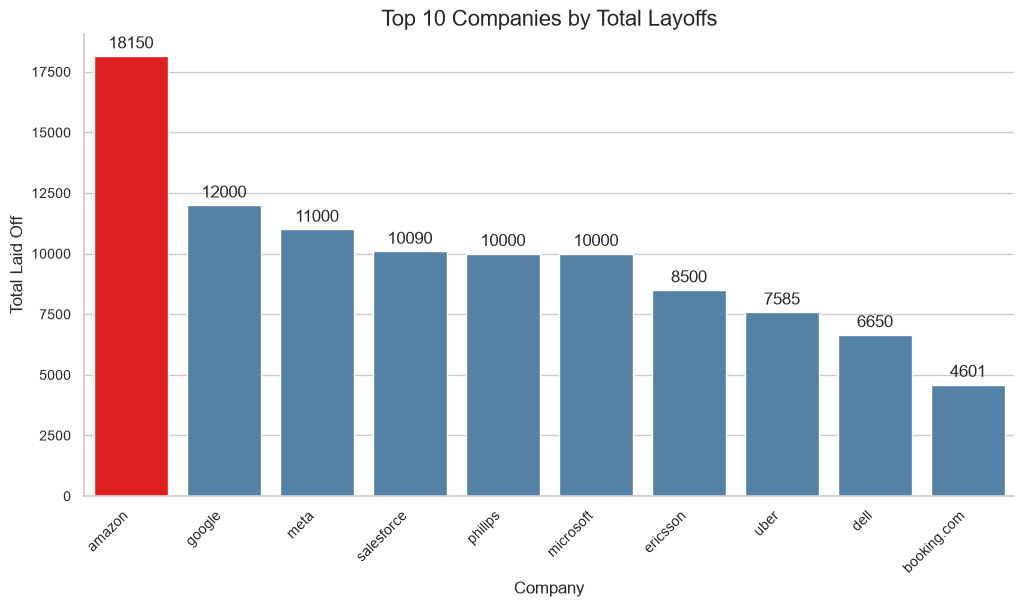

In [73]:
# Top 10 Companies by Total Layoffs

top_companies = (
    df.groupby("company", as_index=False)["total_laid_off"]
      .sum()
      .sort_values("total_laid_off", ascending=False)
      .head(10)
)

fig, ax = plt.subplots()

sns.barplot(
    data=top_companies,
    x="company",
    y="total_laid_off",
    hue="company",
    palette=["red"] + ["steelblue"] * 9,
    legend=False,
    ax=ax
)

ax.set_title("Top 10 Companies by Total Layoffs")
ax.set_xlabel("Company")
ax.set_ylabel("Total Laid Off")

plt.xticks(rotation=45, ha="right")

for container in ax.containers:
    ax.bar_label(container, padding=3)

sns.despine()

plt.show()

## Total Layoffs by Year

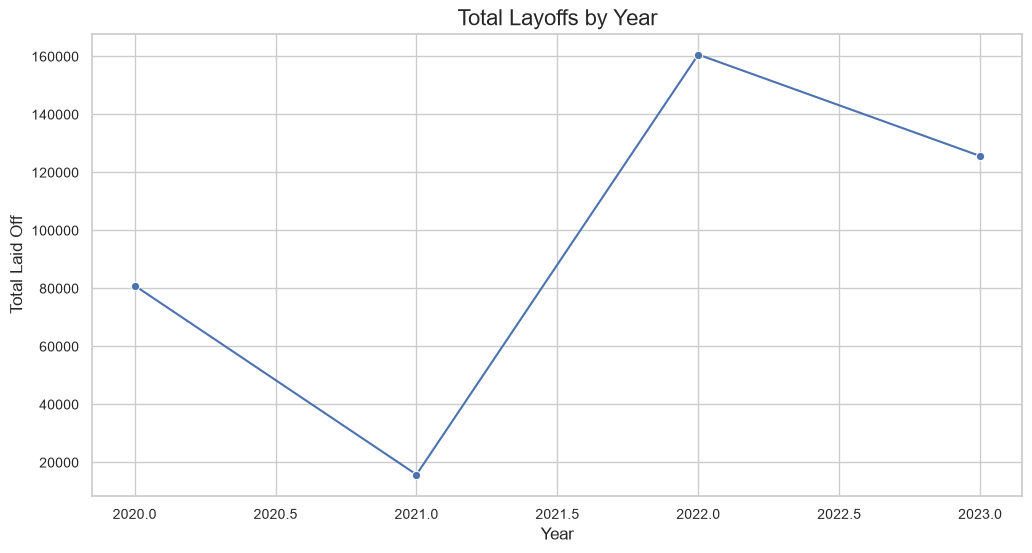

In [74]:
# ==================================================
# Layoffs by Year
# ==================================================
year_layoffs = (
    df.groupby("year")["total_laid_off"]
      .sum()
)

sns.lineplot(
    x=year_layoffs.index,
    y=year_layoffs.values,
    marker="o"
)

plt.title("Total Layoffs by Year")
plt.xlabel("Year")
plt.ylabel("Total Laid Off")

plt.show()

## Top 10 Countries by Total Layoffs

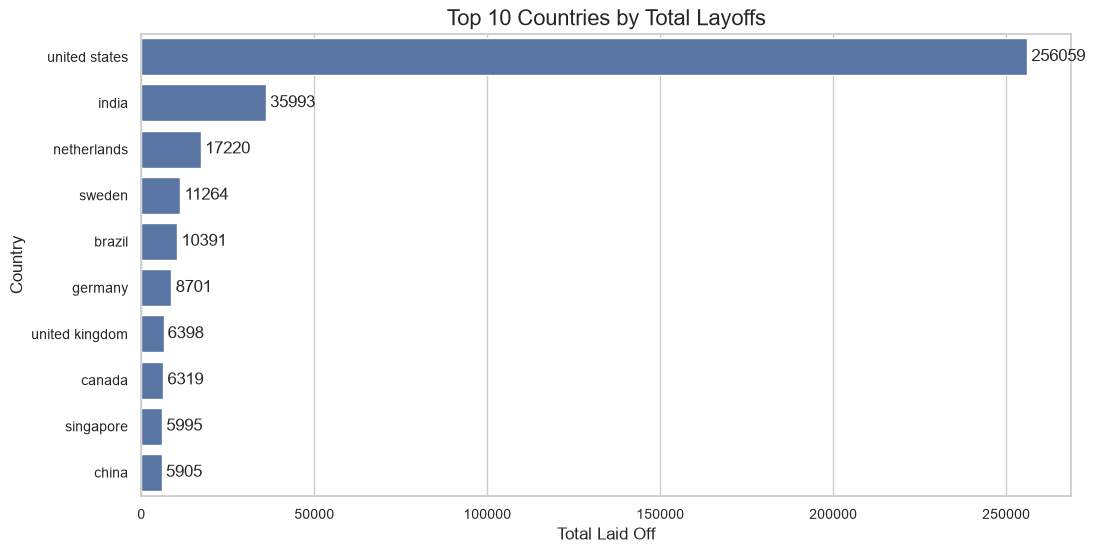

In [75]:
country_layoffs = (
    df.groupby("country")["total_laid_off"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

ax = sns.barplot(
    x=country_layoffs.values,
    y=country_layoffs.index
)

plt.title("Top 10 Countries by Total Layoffs")
plt.xlabel("Total Laid Off")
plt.ylabel("Country")

for container in ax.containers:
    ax.bar_label(
        container,
        padding=3,
        fmt="%.0f"
    )
plt.show()

## Layoffs by Industry

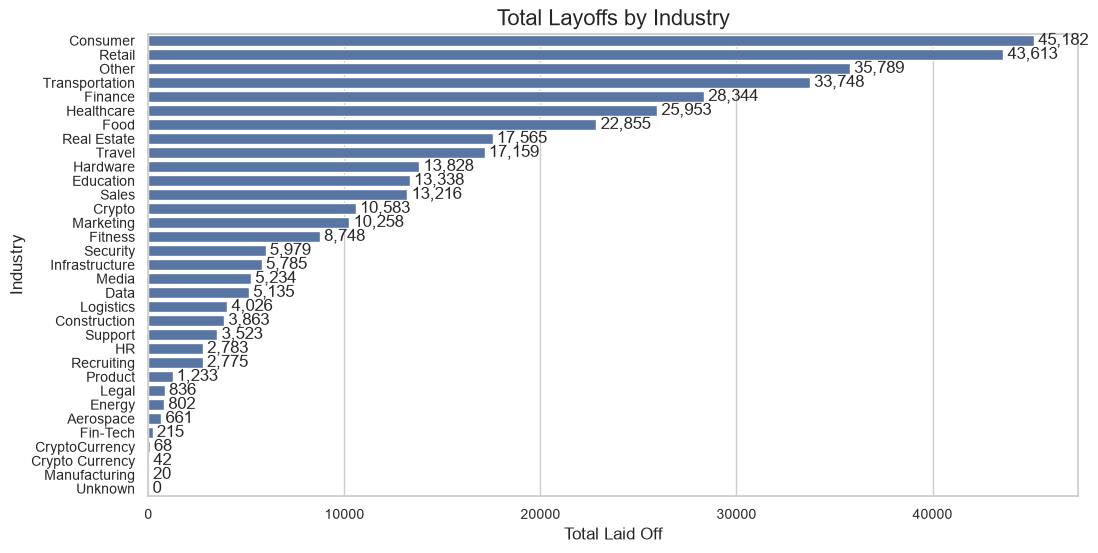

In [76]:
industry_layoffs = (
    df.groupby("industry")["total_laid_off"]
      .sum()
      .sort_values(ascending=False)
)

ax = sns.barplot(
    x=industry_layoffs.values,
    y=industry_layoffs.index
)

plt.title("Total Layoffs by Industry")
plt.xlabel("Total Laid Off")
plt.ylabel("Industry")

for container in ax.containers:
    labels = [f"{bar.get_width():,.0f}" for bar in container]
    ax.bar_label(
        container,
        labels=labels,
        padding=3
    )

plt.show()

## Total Layoffs by Company Stage

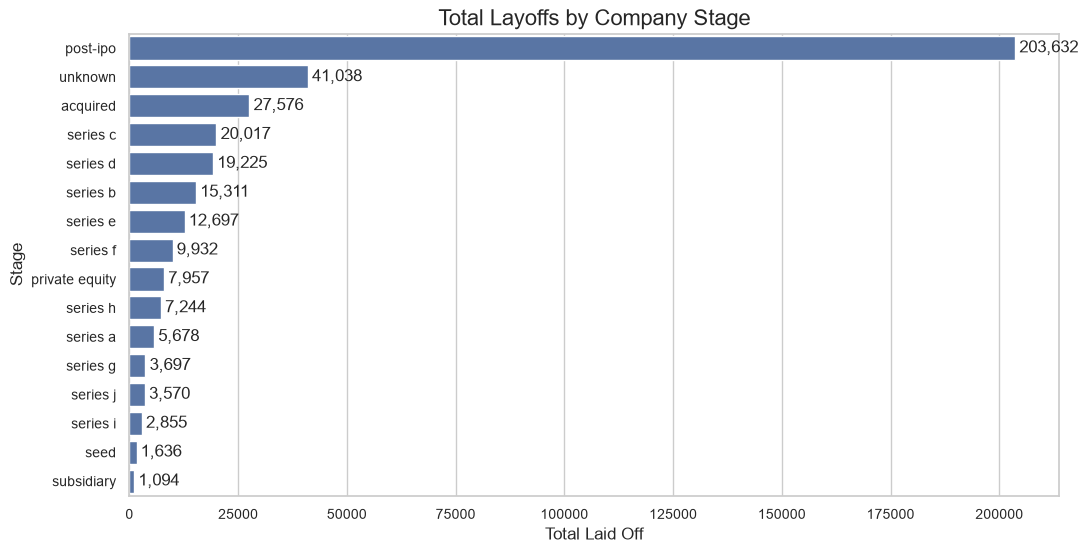

In [77]:
stage_layoffs = (
    df.groupby("stage")["total_laid_off"]
      .sum()
      .sort_values(ascending=False)
)

ax = sns.barplot(
    x=stage_layoffs.values,
    y=stage_layoffs.index
)

plt.title("Total Layoffs by Company Stage")
plt.xlabel("Total Laid Off")
plt.ylabel("Stage")

for container in ax.containers:
    labels = [f"{bar.get_width():,.0f}" for bar in container]
    ax.bar_label(container, labels=labels, padding=3)

plt.show()

## Distribution of Total Layoffs

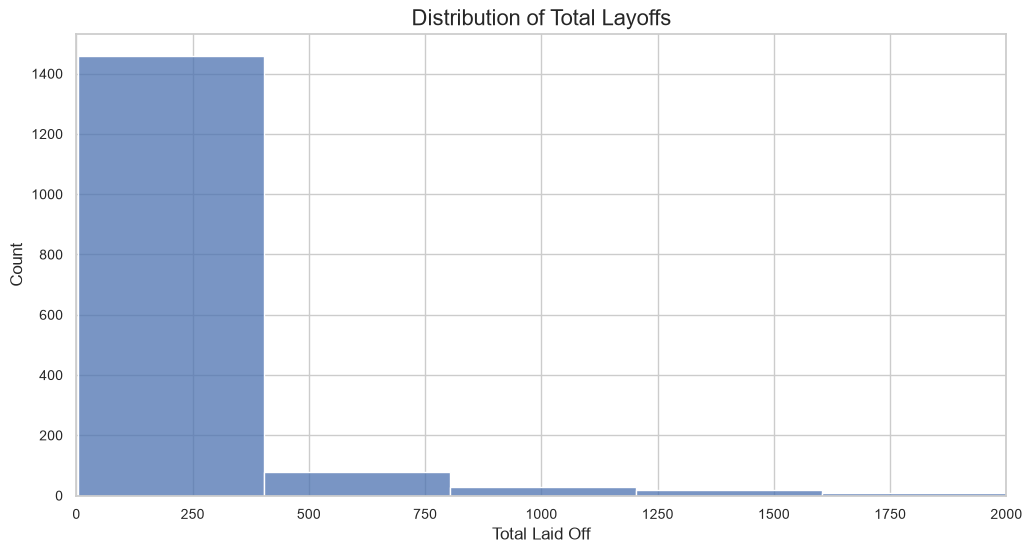

In [78]:
sns.histplot(
    data=df,
    x="total_laid_off",
    bins=30
)

plt.title("Distribution of Total Layoffs")
plt.xlabel("Total Laid Off")
plt.ylabel("Count")
plt.xlim(0, 2000)

plt.show()

## Box Plot of Total Layoffs

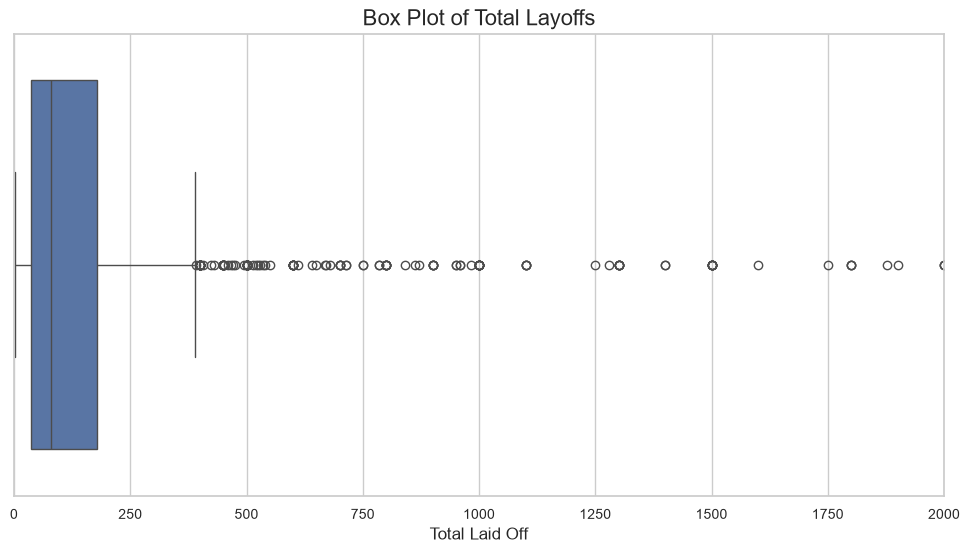

In [79]:
sns.boxplot(
    data=df,
    x="total_laid_off"
)

plt.title("Box Plot of Total Layoffs")
plt.xlabel("Total Laid Off")
plt.xlim(0, 2000)

plt.show()

## Funding vs Total Layoffs by Stage

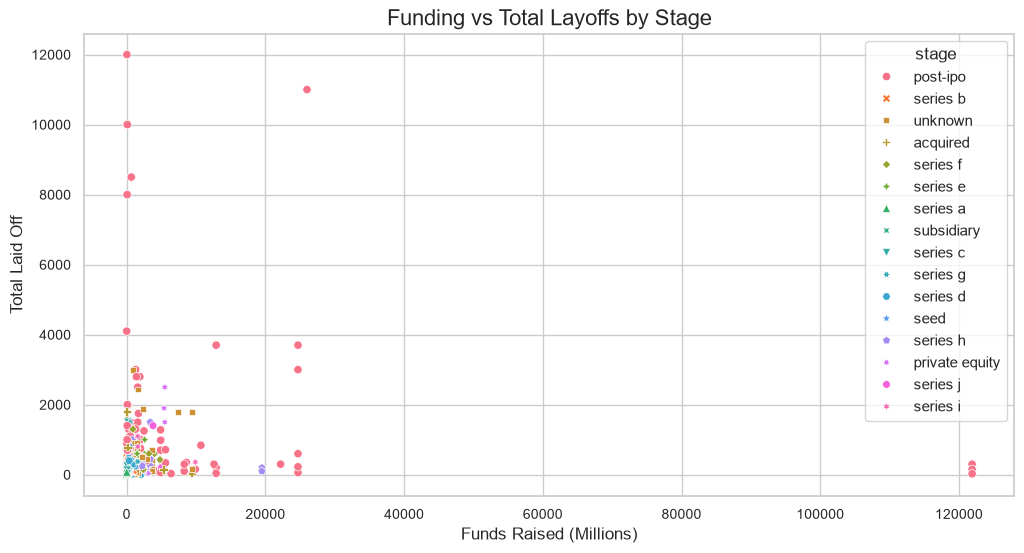

In [80]:
sns.scatterplot(
    data=df,
    x="funds_raised_millions",
    y="total_laid_off",
    hue="stage",
    style="stage"
)

plt.title("Funding vs Total Layoffs by Stage")
plt.xlabel("Funds Raised (Millions)")
plt.ylabel("Total Laid Off")

plt.show()

## Correlation Matrix

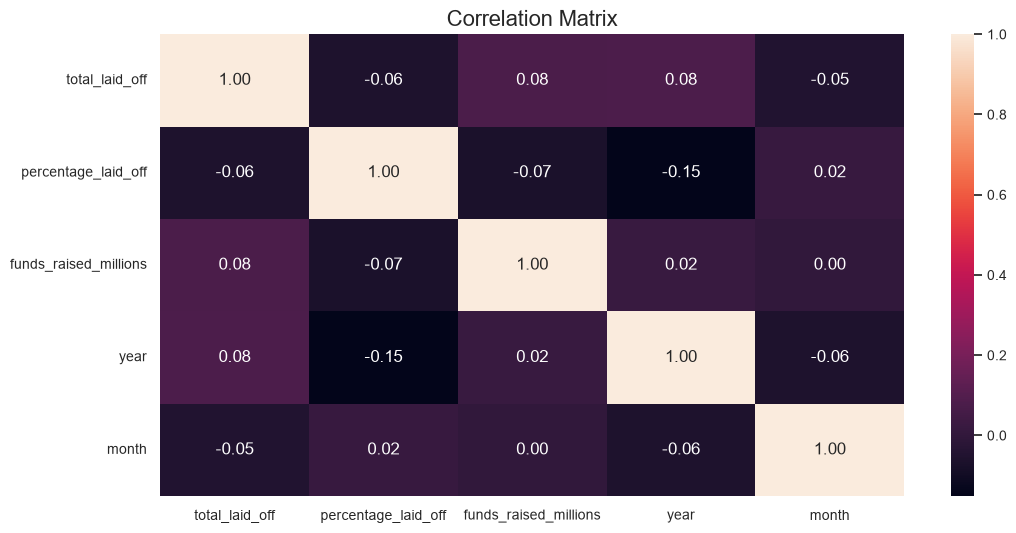

In [81]:
numeric_df = df.select_dtypes(include="number")

corr = numeric_df.corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

# Memory_Usage

In [ ]:
mem_before = df.memory_usage(deep=True).sum() / 1024**2
print(f"💾 Memory usage BEFORE optimization: {mem_before:.2f} MB")

# Per-column breakdown
print("\nTop memory-consuming columns (before):")
print((df.memory_usage(deep=True) / 1024**2).sort_values(ascending=False).head(6).round(3))

💾 Memory usage BEFORE optimization: 0.24 MB

Top memory-consuming columns (before):
company                  0.107
Index                    0.018
percentage_laid_off      0.018
total_laid_off           0.018
date                     0.018
funds_raised_millions    0.018
dtype: float64


In [ ]:
categorical_cols = ['country'
,'location'    
,'company'     
,'stage'      
,'industry'   
,'Index']

for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].astype('category')


# Measure memory after optimization
mem_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"💾 Memory usage AFTER optimization:  {mem_after:.2f} MB")
print(f"🎉 Memory saved: {mem_before - mem_after:.2f} MB ({(1 - mem_after/mem_before)*100:.1f}% reduction)")


💾 Memory usage AFTER optimization:  0.24 MB
🎉 Memory saved: 0.00 MB (0.0% reduction)


# Key Insights

1. Amazon recorded the highest total number of layoffs among the companies analyzed, with 18,150 employees laid off.

2. The United States recorded the highest total number of layoffs among the countries in the dataset, with approximately 256,474 employees affected.

3. The Consumer and Retail industries recorded some of the highest total numbers of layoffs, indicating that workforce reductions were particularly significant in these sectors.

4. 2022 recorded the highest total number of layoffs in the dataset, with 161,711 employees affected, accounting for approximately 41.9% of all recorded layoffs.

5. Post-IPO companies accounted for the largest share of total layoffs, with 204,882 employees affected. This indicates that large-scale layoffs were not limited to early-stage startups.

6. The distribution of total layoffs is highly right-skewed. Most companies experienced relatively small workforce reductions, while a small number of companies recorded exceptionally large layoffs.

7. The total layoffs variable contains several significant outliers, mainly caused by companies that conducted exceptionally large workforce reductions.

8. There is a very weak linear relationship between funds raised and total layoffs, suggesting that the amount of funding raised alone is not a strong indicator of future workforce reductions.


# Recommendations

1. Companies should regularly evaluate workforce size against business demand and operational needs to reduce the risk of large-scale layoffs.

2. Companies should maintain appropriate financial reserves and carefully manage expenses to better handle periods of economic uncertainty.

3. Business leaders and investors should closely monitor industries with high levels of layoffs and investigate the factors contributing to workforce reductions.

4. Companies should not rely on funding size alone as an indicator of workforce stability. Funding should be supported by sustainable growth and effective financial planning.

5. Organizations should continuously monitor workforce, financial, and operational metrics to identify potential risks early and support data-driven decision making.

# Conclusion

This project analyzed layoffs data to identify major patterns across companies, countries, industries, company stages, and years.

The analysis showed that layoffs were concentrated in a relatively small number of companies and that 2022 experienced a particularly high level of workforce reductions. The data also showed a weak linear relationship between funding raised and total layoffs.

Overall, the project demonstrates how data cleaning, exploratory data analysis, and visualization can be used to identify meaningful patterns and support data-driven business decisions.